In [ ]:
---
execute:
  eval: false
  echo: true
  warning: false
format:
  html:
    code-fold: false
---

Importing the packages.

In [1]:
#| echo: true
import torch
import deepinv as dinv
from diffusers import AutoencoderKL, UNet2DConditionModel, DDIMScheduler
from transformers import CLIPTextModel, CLIPTokenizer
import matplotlib.pyplot as plt
from PIL import Image
import requests
from torchvision import transforms

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

Creating an inpaiting problem.

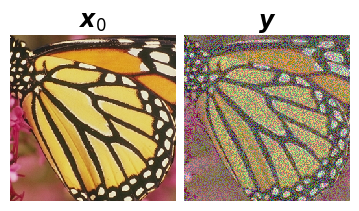

In [2]:
#| echo: true
x = dinv.utils.load_example("butterfly.png", device=device)

transform = transforms.Compose([
    transforms.Normalize([0.5], [0.5])
])
x_true = transform(x).to(device)

keep_probability = 0.5
mask = (torch.rand((1, 3, 256, 256), device=device) < keep_probability).float()

physics = dinv.physics.Inpainting(
    img_size=(3, 256, 256),
    mask=mask,
    device=device
)

y = physics(x_true)

dinv.utils.plotting.plot([x_true, y], titles=[r"$\boldsymbol{x}_0$", r"$\boldsymbol{y}$"])

Loading a pre-trained LDM.

In [ ]:
#| echo: true
model_id = "runwayml/stable-diffusion-v1-5"

vae = AutoencoderKL.from_pretrained(model_id, subfolder="vae").to(device)
unet = UNet2DConditionModel.from_pretrained(model_id, subfolder="unet").to(device)

tokenizer = CLIPTokenizer.from_pretrained(model_id, subfolder="tokenizer")
text_encoder = CLIPTextModel.from_pretrained(model_id, subfolder="text_encoder").to(device)
empty_tokens = tokenizer([""], padding="max_length", max_length=tokenizer.model_max_length, return_tensors="pt").input_ids.to(device)
with torch.no_grad():
    empty_embeds = text_encoder(empty_tokens)[0].detach()

Reconstructing the image using PSLD.

In [ ]:
#| echo: true
eta = 0.005
gamma = 0.01
data_fidelity = dinv.optim.data_fidelity.L2()

scheduler = DDIMScheduler.from_pretrained(model_id, subfolder="scheduler")
scheduler.set_timesteps(100)
alphas_cumprod = scheduler.alphas_cumprod.to(device)

z_t = torch.randn((1, unet.config.in_channels, 32, 32), device=device)

for i, t in enumerate(scheduler.timesteps):
    z_t = z_t.requires_grad_(True)
    noise_pred = unet(z_t, t, encoder_hidden_states=empty_embeds).sample

    alpha_bar = alphas_cumprod[t]

    z_hat_0 = (z_t - (1 - alpha_bar).sqrt() * noise_pred) / alpha_bar.sqrt()
    x_hat_0 = vae.decode(z_hat_0 / vae.config.scaling_factor).sample

    loss_meas = data_fidelity(x_hat_0, y, physics)

    y_proj = physics.A_adjoint(y)
    x_proj_A = physics.A_adjoint(physics.A(x_hat_0))

    x_glued = y_proj + (x_hat_0 - x_proj_A)
    z_glued = vae.encode(x_glued).latent_dist.mean * vae.config.scaling_factor

    loss_reg = torch.linalg.norm(z_hat_0 - z_glued.detach())

    grad_meas = torch.autograd.grad(outputs=loss_meas, inputs=z_t, retain_graph=True)[0]
    grad_reg = torch.autograd.grad(outputs=loss_reg, inputs=z_t)[0]

    with torch.no_grad():
        prev_sample = scheduler.step(noise_pred, t, z_t).prev_sample

    z_t = (prev_sample - eta * grad_meas - gamma * grad_reg).detach()

with torch.no_grad():
    x_recon = vae.decode(z_t / vae.config.scaling_factor).sample

Plotting the results.

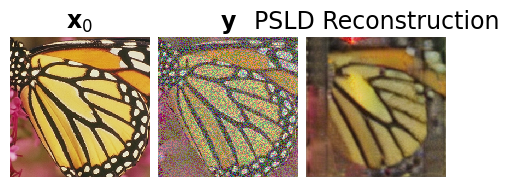

In [29]:
#| echo: true
imgs = [x_true, y, x_recon]
titles = [r"$\mathbf{x}_0$", r"$\mathbf{y}$", r"PSLD Reconstruction"]

dinv.utils.plotting.plot(imgs, titles=titles, cmap="gray")